# Assignment 4: Machine Learning Model Application & Evaluation
**Course:** Introduction to Data Science
**Name:** Areeb Fatima | **Roll No:** SU92-BCSFM-F26-039

## 1. Introduction and Problem Definition
- **Dataset:** Melbourne Housing Snapshot (Kaggle), 13,579 house sales
  (https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot)
- **Data preparation:** The data was cleaned in Assignment 2 and explored in Assignment 3 (EDA).
  This notebook loads the cleaned file `cleaned_melbourne_housing.csv`.
- **Target (y):** `Price`, the selling price of a house
- **Features (X):** 21 columns: Rooms, Type, Distance, Bathroom, Car, Landsize, BuildingArea,
  YearBuilt, CouncilArea, Lattitude, Longtitude, Regionname, Propertycount, house_age, age_group,
  sale_year, sale_month, Year, Month, building_area_missing, year_built_missing
- **Problem type:** Regression, because the target is a continuous number
- **Goal:** Predict the house price and compare three models (Linear Regression, Decision Tree,
  Random Forest) to find the best one.

**Steps in this notebook:** load data, train-test split, train models, evaluate (MAE, RMSE, R²),
compare, and write a final conclusion.

## 2. Loading the Data
The cleaned dataset was loaded. It has **13,579 rows and 29 columns**. The `Date` column was converted
to datetime format, and `Year` and `Month` columns were created from it. The `Price` column is
numerical, so this is a regression problem.

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("/kaggle/input/datasets/areeb112/cleaned-melbourne-housing-csv/cleaned_melbourne_housing.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

print(df.shape)
print(df.columns.tolist())
df.head()

(13579, 29)
['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude', 'Regionname', 'Propertycount', 'sale_year', 'sale_month', 'house_age', 'building_area_missing', 'year_built_missing', 'age_group', 'Year', 'Month']


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Regionname,Propertycount,sale_year,sale_month,house_age,building_area_missing,year_built_missing,age_group,Year,Month
0,Abbotsford,85 Turner St,2,house,1480000.0,sold,Biggin,2016-03-12,2.5,3067,...,Northern Metropolitan,4019.0,2016,12,NaN,1,1,NaN,2016.0,3.0
1,Abbotsford,25 Bloomburg St,2,house,1035000.0,sold,Biggin,2016-04-02,2.5,3067,...,Northern Metropolitan,4019.0,2016,2,116.0,0,0,historic,2016.0,4.0
2,Abbotsford,5 Charles St,3,house,1465000.0,sold_prior,Biggin,2017-04-03,2.5,3067,...,Northern Metropolitan,4019.0,2017,3,117.0,0,0,historic,2017.0,4.0
3,Abbotsford,40 Federation La,3,house,850000.0,passed_in,Biggin,2017-04-03,2.5,3067,...,Northern Metropolitan,4019.0,2017,3,NaN,1,1,NaN,2017.0,4.0
4,Abbotsford,55a Park St,4,house,1600000.0,vendor_bid,Nelson,2016-04-06,2.5,3067,...,Northern Metropolitan,4019.0,2016,6,2.0,0,0,new,2016.0,4.0


## 3. Train-Test Split and Preprocessing
- Columns that are too specific or repeated were removed: Address, Suburb, Postcode, SellerG,
  Bedroom2, Date and Method.
- The data was split **80% training (10,863 rows)** and **20% testing (2,716 rows)**.
  The models learn only from the training data and are tested on unseen test data.
- **Missing values** were filled using the median (numbers) or most frequent value (categories),
  learned from the training data only, to avoid data leakage.
- **Categorical columns** (Type, Regionname, CouncilArea, age_group) were converted using One-Hot Encoding.
- **Scaling** (StandardScaler) was used only for Linear Regression, because tree-based models do not need it.

In [7]:
drop_cols = ["Address", "Suburb", "Postcode", "SellerG", "Bedroom2", "Date", "Method"]
df_model = df.drop(columns=drop_cols, errors="ignore")

X = df_model.drop("Price", axis=1)
y = df_model["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                     ("oh", OneHotEncoder(handle_unknown="ignore"))])

prep_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", cat_pipe, cat_cols)])

prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", cat_pipe, cat_cols)])

print("Features used:", X.columns.tolist())
print("Train:", X_train.shape, "Test:", X_test.shape)

Features used: ['Rooms', 'Type', 'Distance', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude', 'Regionname', 'Propertycount', 'sale_year', 'sale_month', 'house_age', 'building_area_missing', 'year_built_missing', 'age_group', 'Year', 'Month']
Train: (10863, 21) Test: (2716, 21)


## 4. Model Results and Comparison

| Model | MAE | RMSE | R² (Test) | R² (Train) |
|---|---|---|---|---|
| Linear Regression | 251,814 | 371,768 | 0.640 | 0.624 |
| Decision Tree | 231,493 | 398,983 | 0.586 | 1.000 |
| Random Forest | 168,051 | 290,988 | 0.780 | 0.971 |

### Interpretation
- **Linear Regression:** Train R² (0.624) and test R² (0.640) are close but low, so the model is too
  simple for house prices (underfitting).
- **Decision Tree:** Train R² is 1.000 but test R² is only 0.586. It memorized the training data,
  which is clear overfitting. It also has the highest RMSE, so it makes some very large errors.
- **Random Forest:** It has the lowest MAE and RMSE and the highest test R². Averaging many trees
  makes it more stable than a single tree.

In [8]:
models = {
    "Linear Regression": Pipeline([("prep", prep_linear), ("m", LinearRegression())]),
    "Decision Tree": Pipeline([("prep", prep_tree),
                               ("m", DecisionTreeRegressor(random_state=42))]),
    "Random Forest": Pipeline([("prep", prep_tree),
                               ("m", RandomForestRegressor(n_estimators=100,
                                                           random_state=42, n_jobs=-1))]),
}

results, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Test": r2_score(y_test, pred),
        "R2 Train": r2_score(y_train, model.predict(X_train)),
    })

comparison = pd.DataFrame(results).round(3)
comparison

,Model,MAE,RMSE,R2 Test,R2 Train
0,Linear Regression,251813.805,371768.039,0.640,0.624
1,Decision Tree,231493.015,398982.647,0.586,1.000
2,Random Forest,168050.800,290988.254,0.780,0.971


## 5. Actual vs Predicted Prices
The red dashed line is perfect prediction. The closer the points are to it, the better the model.
- Random Forest is closest to the line, so its predictions are the most accurate.
- Linear Regression is spread out and even predicts some negative prices.
- The Decision Tree has many points far from the line.
- All three models under-predict the most expensive houses (above about 3 million), because there are
  few such houses to learn from.

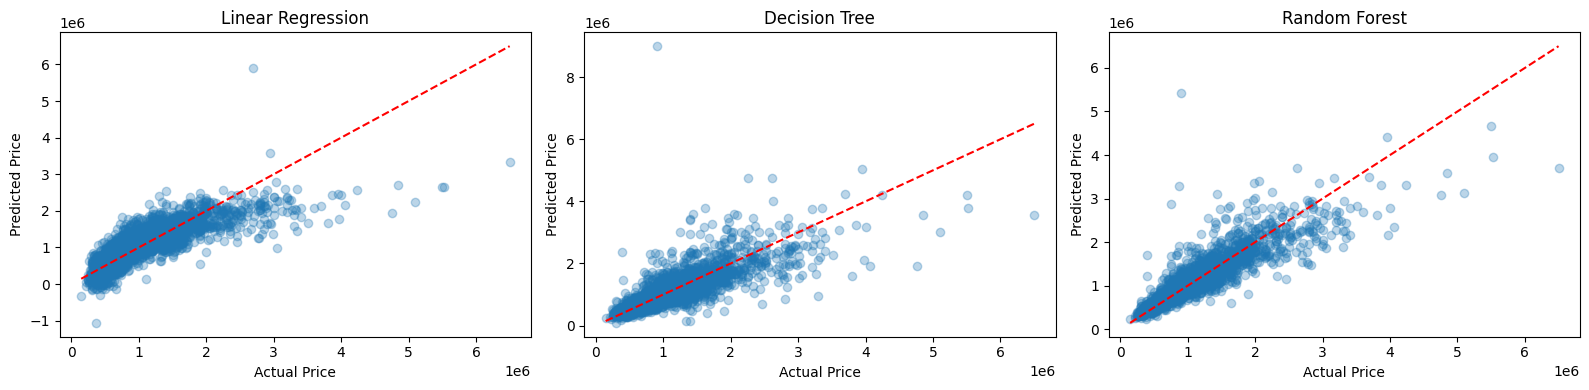

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pred) in zip(axes, preds.items()):
    ax.scatter(y_test, pred, alpha=0.3)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")
plt.tight_layout()
plt.show()

## 6. Most Important Features (Random Forest)
The most important features for predicting price are:
1. **Regionname (Southern Metropolitan)**, the strongest feature
2. **Rooms**
3. **Distance** from the city centre
4. **Landsize**
5. **Type (unit)**

This shows that location and house size matter most for price in Melbourne, which matches the
patterns found in the EDA.

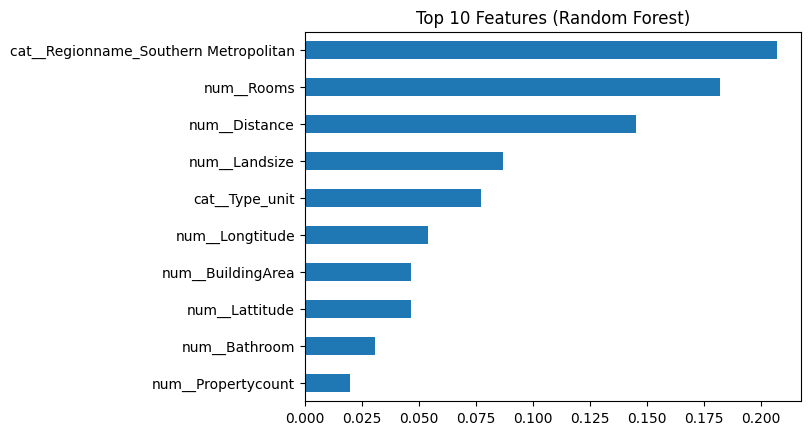

In [10]:
rf = models["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=names).nlargest(10)
imp.sort_values().plot(kind="barh", title="Top 10 Features (Random Forest)")
plt.show()

## 7. Final Conclusion
1. **Best model:** Random Forest, with the lowest MAE (about 168,051) and RMSE (about 290,988)
   and the highest test R² (0.780).
2. **Main metric:** MAE, supported by RMSE and R².
3. **Why MAE matters here:** MAE is in dollars, so it says the model is wrong by about $168,000 on
   average, which a buyer or seller can understand. RMSE is larger than MAE for every model because
   expensive houses cause big errors, and RMSE punishes these more. R² = 0.78 means the model explains
   about 78% of the variation in price.
4. **Overfitting or underfitting:** The Decision Tree overfits strongly (train R² 1.000, test 0.586).
   Random Forest overfits a little (0.971 vs 0.780) but still performs best on unseen data.
   Linear Regression underfits, with a low R² on both train and test (0.624 and 0.640).
5. **Note:** The best model is not chosen by one number only. The Decision Tree has a lower MAE than
   Linear Regression but a worse RMSE and R². Random Forest is also slower and harder to explain than
   Linear Regression.